## Step 0 · Imports

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid")

DATA_DIR = Path("data")
FIG_DIR = Path("reports")

## Step 1 · Load data

In [2]:
train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")

TARGET = "loan_paid_back"
ID = "id"

print("train:", train.shape, " test:", test.shape)

print("\n===== TRAIN (first 5 rows) =====")
display(train.head())

print("\n===== TEST (first 5 rows) =====")
display(test.head())

train: (593994, 13)  test: (254569, 12)

===== TRAIN (first 5 rows) =====


,id,annual_income,debt_to_income_ratio,credit_score,loan_amount,interest_rate,gender,marital_status,education_level,employment_status,loan_purpose,grade_subgrade,loan_paid_back
0,0,29367.99,0.084,736,2528.42,13.67,Female,Single,High School,Self-employed,Other,C3,1.0
1,1,22108.02,0.166,636,4593.10,12.92,Male,Married,Master's,Employed,Debt consolidation,D3,0.0
2,2,49566.20,0.097,694,17005.15,9.76,Male,Single,High School,Employed,Debt consolidation,C5,1.0
3,3,46858.25,0.065,533,4682.48,16.10,Female,Single,High School,Employed,Debt consolidation,F1,1.0
4,4,25496.70,0.053,665,12184.43,10.21,Male,Married,High School,Employed,Other,D1,1.0



===== TEST (first 5 rows) =====


,id,annual_income,debt_to_income_ratio,credit_score,loan_amount,interest_rate,gender,marital_status,education_level,employment_status,loan_purpose,grade_subgrade
0,593994,28781.05,0.049,626,11461.42,14.73,Female,Single,High School,Employed,Other,D5
1,593995,46626.39,0.093,732,15492.25,12.85,Female,Married,Master's,Employed,Other,C1
2,593996,54954.89,0.367,611,3796.41,13.29,Male,Single,Bachelor's,Employed,Debt consolidation,D1
3,593997,25644.63,0.110,671,6574.30,9.57,Female,Single,Bachelor's,Employed,Debt consolidation,C3
4,593998,25169.64,0.081,688,17696.89,12.80,Female,Married,PhD,Employed,Business,C1


**Interpretation**
- Train has 593,994 rows and 13 columns; test has 254,569 rows and 12 columns.
- Test has no `loan_paid_back` column — the answers are hidden for Kaggle scoring.
- Each row is one loan application; `id` is only an identifier and will not be used as a feature.

## Step 2 · Structural audit

In [3]:
train.info()

NUM_COLS = ["annual_income", "debt_to_income_ratio", "credit_score", "loan_amount", "interest_rate"]
CAT_COLS = ["gender", "marital_status", "education_level", "employment_status", "loan_purpose", "grade_subgrade"]
FEATURES = NUM_COLS + CAT_COLS

assert set(FEATURES + [ID, TARGET]) == set(train.columns)
print("Numeric:", NUM_COLS)
print("Categorical:", CAT_COLS)
 

<class 'pandas.DataFrame'>
RangeIndex: 593994 entries, 0 to 593993
Data columns (total 13 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   id                    593994 non-null  int64  
 1   annual_income         593994 non-null  float64
 2   debt_to_income_ratio  593994 non-null  float64
 3   credit_score          593994 non-null  int64  
 4   loan_amount           593994 non-null  float64
 5   interest_rate         593994 non-null  float64
 6   gender                593994 non-null  str    
 7   marital_status        593994 non-null  str    
 8   education_level       593994 non-null  str    
 9   employment_status     593994 non-null  str    
 10  loan_purpose          593994 non-null  str    
 11  grade_subgrade        593994 non-null  str    
 12  loan_paid_back        593994 non-null  float64
dtypes: float64(5), int64(2), str(6)
memory usage: 58.9 MB
Numeric: ['annual_income', 'debt_to_income_ratio', 'credit_sc

**Interpretation**
- All 13 columns have the expected data types: 5 numeric features, 6 categorical features, plus `id` and the target.
- `loan_paid_back` was stored as float (1.0 / 0.0) even though it only contains 0 and 1.

### Target Check

In [4]:
print("Unique values:", sorted(train[TARGET].unique())) 
train[TARGET] = train[TARGET].astype(int)

balance = train[TARGET].value_counts(normalize=True).rename({1: "repaid (1)", 0: "not repaid (0)"})
print((balance * 100).round(2))

Unique values: [np.float64(0.0), np.float64(1.0)]
loan_paid_back
repaid (1)        79.88
not repaid (0)    20.12
Name: proportion, dtype: float64


**Interpretation**
- The target only contains 0 and 1, so I cast it to integer.
- 79.88% of loans were repaid and 20.12% were not — the classes are **imbalanced**.
- **Decision:** accuracy would be misleading (always predicting "repaid" gives ~80%), so I will use ROC AUC and recall on the "not repaid" class.

## Step 3 · Missing values

In [5]:
missing = pd.DataFrame({
    "train_missing": train.isna().sum(),
    "test_missing": test.isna().sum(),
})
missing["train_%"] = (missing["train_missing"] / len(train) * 100).round(2)
print(missing)

                      train_missing  test_missing  train_%
annual_income                     0           0.0      0.0
credit_score                      0           0.0      0.0
debt_to_income_ratio              0           0.0      0.0
education_level                   0           0.0      0.0
employment_status                 0           0.0      0.0
gender                            0           0.0      0.0
grade_subgrade                    0           0.0      0.0
id                                0           0.0      0.0
interest_rate                     0           0.0      0.0
loan_amount                       0           0.0      0.0
loan_paid_back                    0           NaN      0.0
loan_purpose                      0           0.0      0.0
marital_status                    0           0.0      0.0


**Interpretation**
- No missing values in any column, in either train or test.
- **Decision:** no imputation is needed.

## Step 4 · Duplicates

In [6]:
n_dup = train.duplicated(subset=FEATURES).sum()
n_conflict = (train.groupby(FEATURES)[TARGET].nunique() > 1).sum()
print("Duplicate rows:", n_dup)
print("Same features, conflicting label:", n_conflict)

Duplicate rows: 0
Same features, conflicting label: 0


**Interpretation**
- No duplicate rows and no rows with identical features but conflicting labels.
- **Decision:** no rows need to be removed.

## Step 5 · Boundary audit

In [7]:
summary = train[NUM_COLS].describe().T.round(2)
summary["count"] = summary["count"].astype(int)
display(summary)

,count,mean,std,min,25%,50%,75%,max
annual_income,593994,48212.20,26711.94,6002.43,27934.40,46557.68,60981.32,393381.74
debt_to_income_ratio,593994,0.12,0.07,0.01,0.07,0.10,0.16,0.63
credit_score,593994,680.92,55.42,395.00,646.00,682.00,719.00,849.00
loan_amount,593994,15020.30,6926.53,500.09,10279.62,15000.22,18858.58,48959.95
interest_rate,593994,12.36,2.01,3.20,10.99,12.37,13.68,20.99


In [8]:
RULES = {
    "annual_income":        (0, 10_000_000),
    "debt_to_income_ratio": (0, 5),
    "credit_score":         (300, 850),
    "loan_amount":          (1, 10_000_000),
    "interest_rate":        (0, 100),
}

rows = []
for col, (lo, hi) in RULES.items():
    for name, df in [("train", train), ("test", test)]:
        rows.append({
            "column": col,
            "set": name,
            "rule_min": lo,
            "rule_max": hi,
            "actual_min": round(df[col].min(), 2),
            "actual_max": round(df[col].max(), 2),
            "violations": int(((df[col] < lo) | (df[col] > hi)).sum()),
        })

boundary_audit = pd.DataFrame(rows)
display(boundary_audit)

,column,set,rule_min,rule_max,actual_min,actual_max,violations
0,annual_income,train,0,10000000,6002.43,393381.74,0
1,annual_income,test,0,10000000,6011.77,380653.94,0
2,debt_to_income_ratio,train,0,5,0.01,0.63,0
3,debt_to_income_ratio,test,0,5,0.01,0.63,0
4,credit_score,train,300,850,395.00,849.00,0
5,credit_score,test,300,850,395.00,849.00,0
6,loan_amount,train,1,10000000,500.09,48959.95,0
7,loan_amount,test,1,10000000,500.05,48959.26,0
8,interest_rate,train,0,100,3.20,20.99,0
9,interest_rate,test,0,100,3.20,21.29,0


In [9]:
fixed = 0
for col, (lo, hi) in RULES.items():
    for name, df in [("train", train), ("test", test)]:
        bad = (df[col] < lo) | (df[col] > hi)
        if bad.any():
            df.loc[bad, col] = np.nan
            fixed += bad.sum()
            print(f"{name} | {col}: {bad.sum()} values set to NaN")

print(f"Boundary fix done. Total values fixed: {fixed}")

Boundary fix done. Total values fixed: 0


**Interpretation**
- All values fall within business rules (e.g., credit scores 395–849, within the FICO range of 300–850; no negative income or DTI).
- Zero violations in both train and test, so no values were corrected.
- For annual income and DTI, the mean is higher than the median and the max is far above the 75th percentile — an early sign of right skew.

## Step 6 · Category consistency

In [10]:
rows = []

for col in CAT_COLS:
    train_values = set(train[col].unique())
    test_values = set(test[col].unique())

    new_in_test = test_values - train_values
    has_spaces = any(v != v.strip() for v in train_values)
    case_clash = len({v.strip().lower() for v in train_values}) < len(train_values)
    smallest_pct = train[col].value_counts(normalize=True).min() * 100

    rows.append({
        "column": col,
        "n_levels": len(train_values),
        "has_spaces": has_spaces,
        "case_clash": case_clash,
        "new_in_test": ", ".join(new_in_test) if new_in_test else "none",
        "smallest_level_%": round(smallest_pct, 2),
    })

display(pd.DataFrame(rows))

,column,n_levels,has_spaces,case_clash,new_in_test,smallest_level_%
0,gender,3,False,False,none,0.63
1,marital_status,4,False,False,none,1.11
2,education_level,5,False,False,none,1.86
3,employment_status,5,False,False,none,2.01
4,loan_purpose,8,False,False,none,1.42
5,grade_subgrade,30,False,False,none,0.27


**Interpretation**
- No extra spaces or upper/lower-case conflicts in any category.
- Test contains no categories that are missing from train.
- The smallest category still has over 1,600 borrowers, so no rare-level grouping is needed.
- `grade_subgrade` has 30 levels → I will use ordinal encoding instead of one-hot.

In [11]:
def category_summary(col):
    counts = train[col].value_counts()
    share = counts / len(train) * 100
    payback = train.groupby(col)[TARGET].mean() * 100

    summary = pd.DataFrame({
        "count": counts,
        "share_%": share.round(2),
        "payback_rate_%": payback.round(1),
    })
    return summary


for col in CAT_COLS[:-1]:
    print(f"\n{col}")
    display(category_summary(col))


gender


,count,share_%,payback_rate_%
gender,,,
Female,306175,51.55,80.2
Male,284091,47.83,79.6
Other,3728,0.63,79.5



marital_status


,count,share_%,payback_rate_%
marital_status,,,
Divorced,21312,3.59,79.7
Married,277239,46.67,79.9
Single,288843,48.63,79.9
Widowed,6600,1.11,79.0



education_level


,count,share_%,payback_rate_%
education_level,,,
Bachelor's,279606,47.07,78.9
High School,183592,30.91,81.0
Master's,93097,15.67,80.2
Other,26677,4.49,80.3
PhD,11022,1.86,83.0



employment_status


,count,share_%,payback_rate_%
employment_status,,,
Employed,450645,75.87,89.4
Retired,16453,2.77,99.7
Self-employed,52480,8.84,89.8
Student,11931,2.01,26.4
Unemployed,62485,10.52,7.8



loan_purpose


,count,share_%,payback_rate_%
loan_purpose,,,
Business,35303,5.94,81.3
Car,58108,9.78,80.1
Debt consolidation,324695,54.66,79.7
Education,36641,6.17,77.7
Home,44118,7.43,82.3
Medical,22806,3.84,77.8
Other,63874,10.75,80.2
Vacation,8449,1.42,79.6


In [12]:
grade_summary = category_summary("grade_subgrade").sort_index()
display(grade_summary.T)

grade_subgrade,A1,A2,A3,A4,A5,B1,B2,B3,B4,B5,C1,C2,C3,C4,C5,D1,D2,D3,D4,D5,E1,E2,E3,E4,E5,F1,F2,F3,F4,F5
count,1600.00,2018.00,2066.00,1701.00,2471.00,14344.00,15167.00,13926.00,13877.00,13937.00,53363.00,54443.00,58695.00,55957.00,53317.00,37029.00,34432.0,36694.00,35097.00,32101.0,6891.00,6372.00,7075.00,8036.00,6084.00,5534.00,5203.00,5082.00,5535.00,5947.0
share_%,0.27,0.34,0.35,0.29,0.42,2.41,2.55,2.34,2.34,2.35,8.98,9.17,9.88,9.42,8.98,6.23,5.8,6.18,5.91,5.4,1.16,1.07,1.19,1.35,1.02,0.93,0.88,0.86,0.93,1.0
payback_rate_%,95.20,95.30,95.50,95.70,94.50,91.60,93.70,94.00,93.20,93.40,86.00,85.10,83.60,84.40,84.60,73.20,72.1,69.60,71.50,71.3,65.20,66.30,64.20,65.00,66.90,62.50,61.80,60.40,63.70,63.9


**Interpretation**
- **Employment status is the strongest signal:** only 7.8% of unemployed and 26.4% of student borrowers repaid, versus 89.4% of employed and 99.7% of retired borrowers.
- **Loan grade** shows a clear risk order: A grades repay ~95%, F grades only ~60–64%.
- Gender, marital status, education, and loan purpose show small differences (within ~5 percentage points).
- **Decision:** gender barely affects payback and should not drive credit decisions, so I will exclude it from the model.

## Step 7 · Outliers (Tukey 1.5 × IQR)

In [13]:
def tukey_bounds(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

out_rows = []
for col in NUM_COLS:
    lo, hi = tukey_bounds(train[col])
    is_out = (train[col] < lo) | (train[col] > hi)
    out_rows.append({
        "column": col,
        "lower": round(lo, 3),
        "upper": round(hi, 3),
        "outlier_%": round(is_out.mean() * 100, 2),
        "payback_rate_outliers": round(train.loc[is_out, TARGET].mean(), 3),
        "payback_rate_others": round(train.loc[~is_out, TARGET].mean(), 3),
    })
outliers = pd.DataFrame(out_rows)
display(outliers)

,column,lower,upper,outlier_%,payback_rate_outliers,payback_rate_others
0,annual_income,-21635.980,110551.700,2.68,0.776,0.799
1,debt_to_income_ratio,-0.054,0.282,2.96,0.448,0.810
2,credit_score,536.500,828.500,0.99,0.696,0.800
3,loan_amount,-2588.820,31727.020,0.49,0.761,0.799
4,interest_rate,6.955,17.715,0.86,0.749,0.799


**Interpretation**
- Income and DTI have the most outliers (2.68% and 2.96%), all above the upper bound.
- DTI outliers repaid only **44.8%**, versus **81.0%** for other borrowers.
- **Decision:** these are real high-risk borrowers, not data errors. I keep all outliers and compress income and DTI with a log transform instead of deleting them.

## Step 8 · Box plots

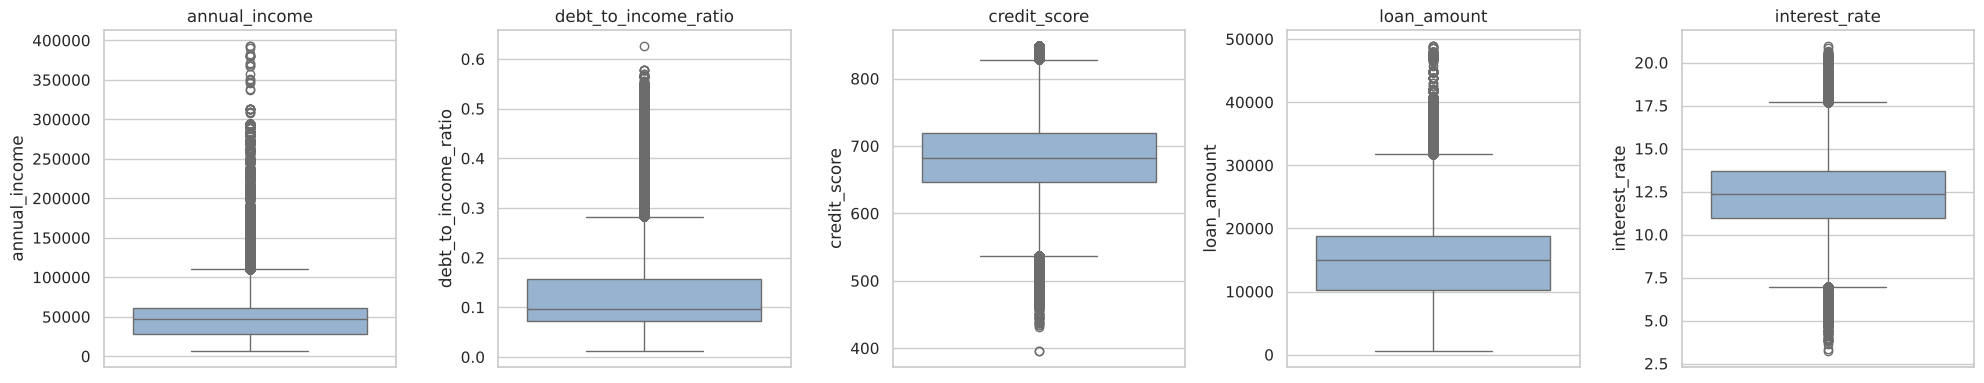

In [14]:
fig, axes = plt.subplots(1, len(NUM_COLS), figsize=(20, 4))
for ax, col in zip(axes, NUM_COLS):
    sns.boxplot(y=train[col], ax=ax, color="#8fb3d9")
    ax.set_title(col)
plt.tight_layout()
plt.savefig(FIG_DIR / "boxplots.png", dpi=120)
plt.show()

**Interpretation**
- Income and DTI show long upper tails with many points above the whisker, confirming right skew.
- Credit score, loan amount, and interest rate look roughly symmetric.

## Step 9 · Skewness and log transform

In [15]:
skew = train[NUM_COLS].skew().round(2)

skew_table = pd.DataFrame({
    "skewness": skew,
    "shape": ["right-skewed" if s > 1 else "roughly symmetric" for s in skew],
})
display(skew_table)

,skewness,shape
annual_income,1.72,right-skewed
debt_to_income_ratio,1.41,right-skewed
credit_score,-0.17,roughly symmetric
loan_amount,0.21,roughly symmetric
interest_rate,0.05,roughly symmetric


**Interpretation**
- Annual income (1.72) and DTI (1.41) are right-skewed (skewness > 1).
- The other three numeric features are roughly symmetric and do not need transformation.

In [16]:
train["log_annual_income"] = np.log1p(train["annual_income"])
train["log_debt_to_income_ratio"] = np.log(train["debt_to_income_ratio"])

test["log_annual_income"] = np.log1p(test["annual_income"])
test["log_debt_to_income_ratio"] = np.log(test["debt_to_income_ratio"])

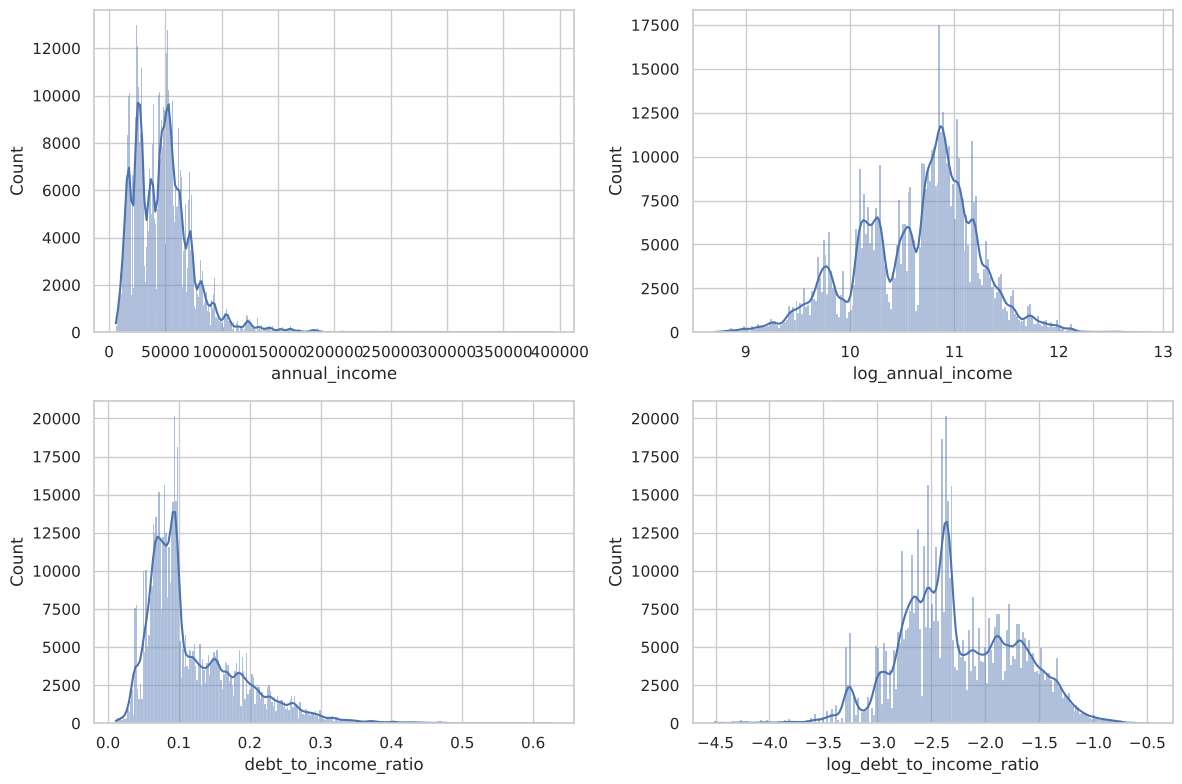

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

sns.histplot(train["annual_income"], kde=True, ax=axes[0, 0])
sns.histplot(train["log_annual_income"], kde=True, ax=axes[0, 1])
sns.histplot(train["debt_to_income_ratio"], kde=True, ax=axes[1, 0])
sns.histplot(train["log_debt_to_income_ratio"], kde=True, ax=axes[1, 1])

plt.tight_layout()
plt.savefig(FIG_DIR / "skewness_before_after.png", dpi=120)
plt.show()

**Interpretation**
- After transformation, both distributions are much more balanced: income skew 1.72 → −0.34, DTI skew 1.41 → 0.08.
- I used `log1p` for income but `log` for DTI: DTI values are all below 1, where `log1p` barely changes the shape. DTI has no zeros (minimum 0.011), so `log` is safe.
- The multiple peaks likely come from the synthetic data generation, not from the transform.

## Step 10 · Correlation heatmap

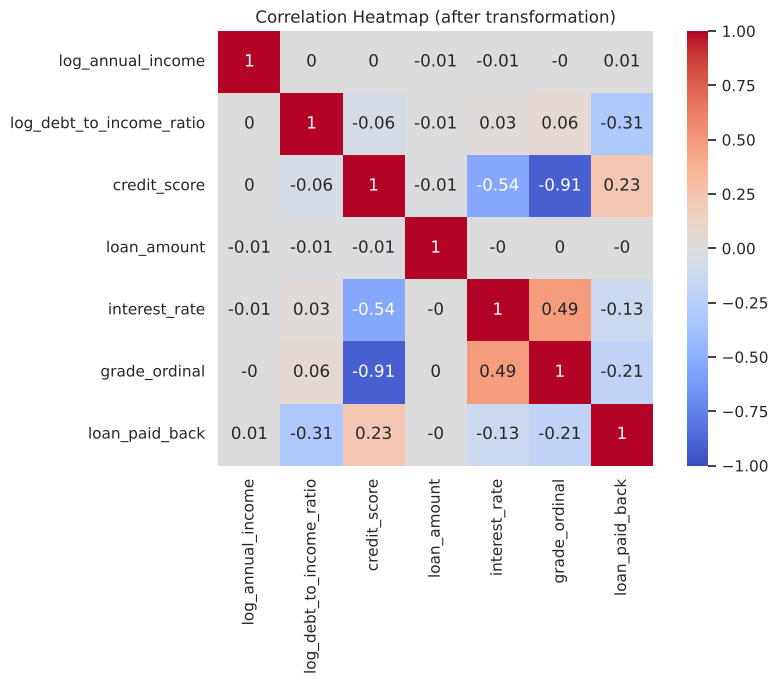

In [18]:

grade_order = [f"{letter}{num}" for letter in "ABCDEF" for num in range(1, 6)]
grade_map = {grade: i + 1 for i, grade in enumerate(grade_order)}


train["grade_ordinal"] = train["grade_subgrade"].map(grade_map)


corr_cols = [
    "log_annual_income",
    "log_debt_to_income_ratio",
    "credit_score",
    "loan_amount",
    "interest_rate",
    "grade_ordinal",
    TARGET,
]
corr = train[corr_cols].corr().round(2)


plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Correlation Heatmap (after transformation)")
plt.tight_layout()
plt.savefig(FIG_DIR / "correlation_heatmap.png", dpi=120)
plt.show()

**Correlation heatmap interpretation**

- **Key drivers of payback:** Debt-to-income ratio has the strongest link (r = −0.31), followed by credit score (r = +0.23) and loan grade (r = −0.21). Income and loan amount show almost no linear relationship with payback.
- **Multicollinearity:** Credit score and grade are highly correlated (r = −0.91), exceeding the 0.85 threshold. The lender's grade is largely based on credit score, so I will keep only one of them in logistic regression.
- **Risk-based pricing:** Lower credit scores come with higher interest rates (r = −0.54), which matches how lenders price risk.

## Step 11 · Visualizations

In [19]:
overall = train[TARGET].mean() * 100

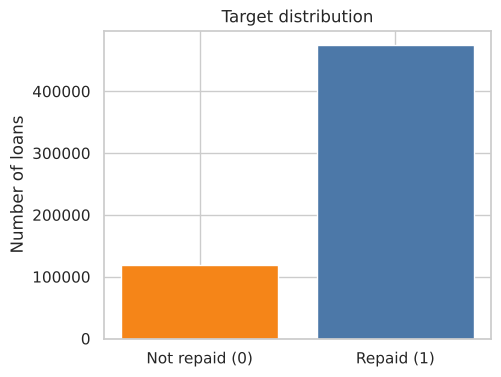

In [20]:
counts = train[TARGET].value_counts().sort_index()

plt.figure(figsize=(5, 4))
plt.bar(["Not repaid (0)", "Repaid (1)"], counts.values, color=["#F58518", "#4C78A8"])
plt.title("Target distribution")
plt.ylabel("Number of loans")
plt.savefig(FIG_DIR / "target_distribution.png", dpi=120)
plt.show()

**Interpretation**
- 79.9% of loans were repaid and 20.1% were not, confirming the class imbalance seen in the target check.

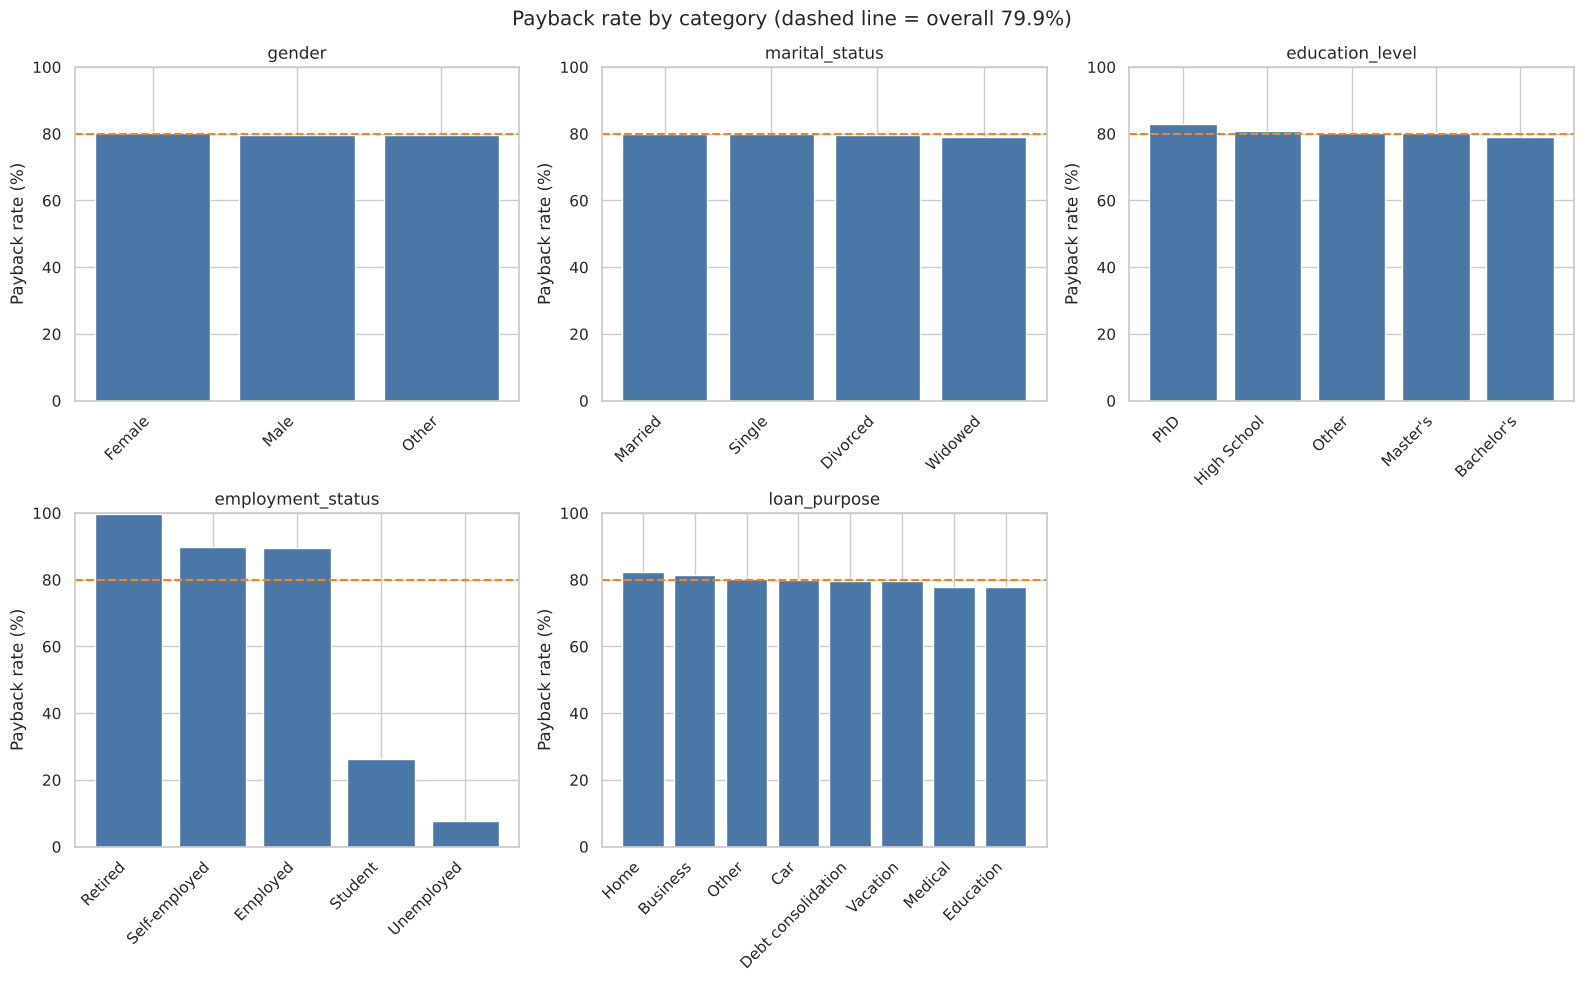

In [21]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

for ax, col in zip(axes.flat, CAT_COLS[:-1]):
    rates = train.groupby(col)[TARGET].mean().sort_values(ascending=False) * 100
    ax.bar(rates.index, rates.values, color="#4C78A8")
    ax.axhline(overall, color="#F58518", linestyle="--")
    ax.set_title(col)
    ax.set_ylabel("Payback rate (%)")
    ax.set_ylim(0, 100)
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")

axes.flat[-1].axis("off")
fig.suptitle(f"Payback rate by category (dashed line = overall {overall:.1f}%)")
plt.tight_layout()
plt.savefig(FIG_DIR / "payback_by_category.png", dpi=120)
plt.show()

**Interpretation**
- Employment status is the only category with a large gap: unemployed (7.8%) and student (26.4%) borrowers sit far below the 79.9% average, while retired borrowers are near 100%.
- Gender, marital status, education, and loan purpose all stay close to the average line.

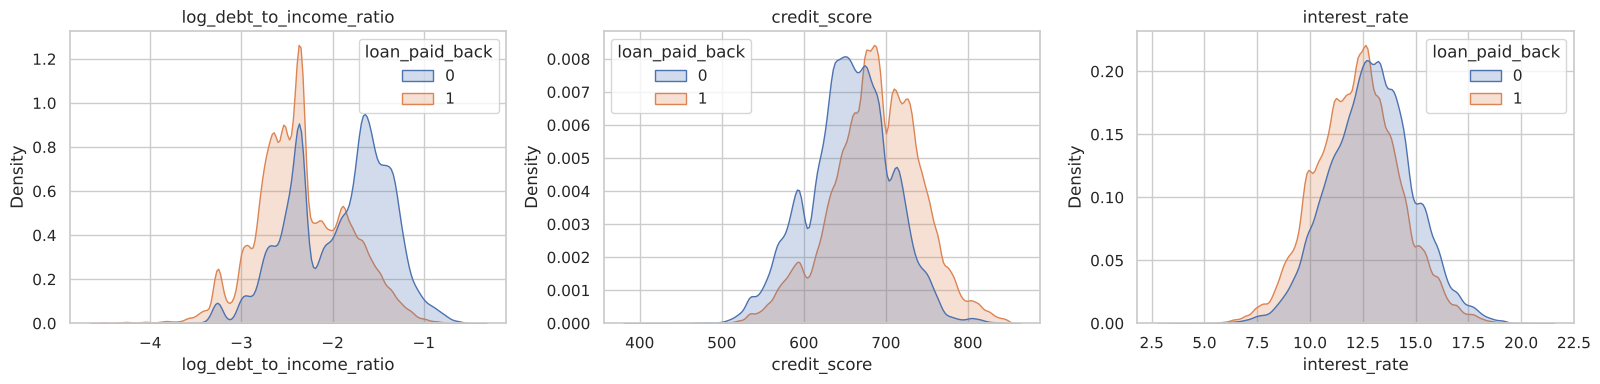

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, col in zip(axes, ["log_debt_to_income_ratio", "credit_score", "interest_rate"]):
    sns.kdeplot(data=train, x=col, hue=TARGET, common_norm=False, fill=True, ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.savefig(FIG_DIR / "numeric_by_target.png", dpi=120)
plt.show()

**Interpretation**
- Borrowers who did not repay have clearly higher log DTI and lower credit scores — the two curves are well separated.
- Interest rate curves overlap more, so it is a weaker signal on its own.

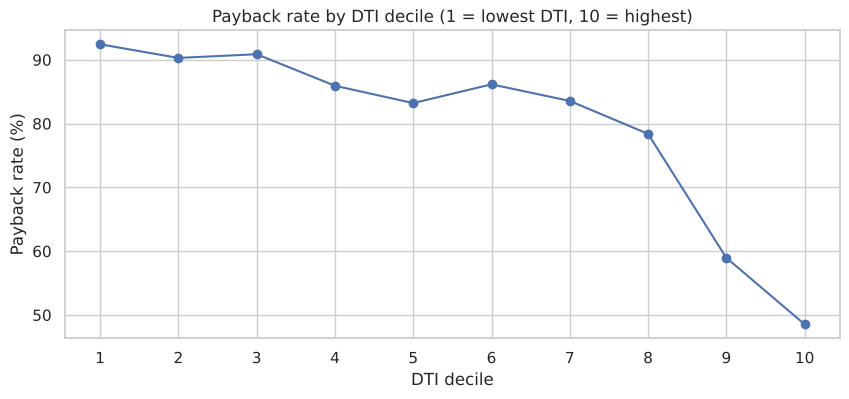

In [23]:
dti_band = pd.qcut(train["debt_to_income_ratio"], 10)
band_rate = train.groupby(dti_band, observed=True)[TARGET].mean() * 100

plt.figure(figsize=(10, 4))
plt.plot(range(1, 11), band_rate.values, marker="o")
plt.xticks(range(1, 11))
plt.title("Payback rate by DTI decile (1 = lowest DTI, 10 = highest)")
plt.xlabel("DTI decile")
plt.ylabel("Payback rate (%)")
plt.savefig(FIG_DIR / "payback_by_dti_decile.png", dpi=120)
plt.show()

**Interpretation**
- Payback falls slowly from 92% to 78% across the first eight DTI deciles, then drops sharply to 59% and 49% in the top two (DTI above ~0.175).
- The relationship is not linear: risk accelerates past a threshold. Tree models can capture this; logistic regression cannot without extra features.

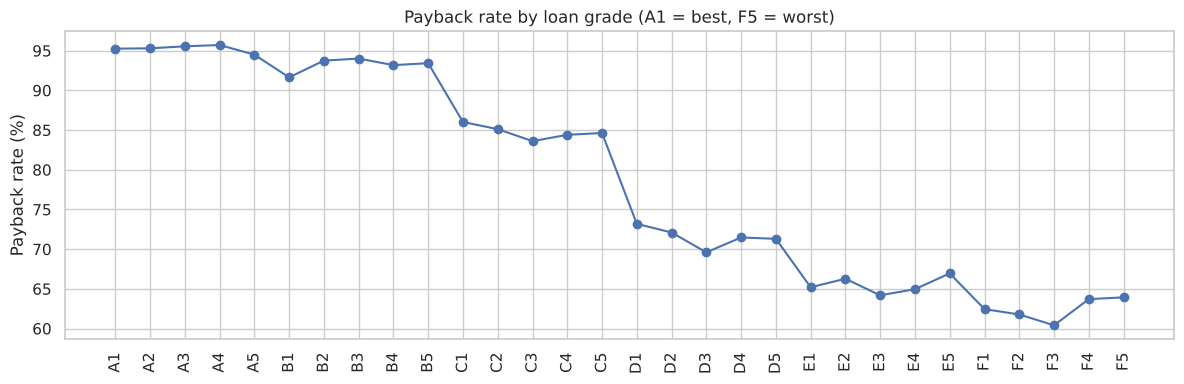

In [24]:
grade_rate = train.groupby("grade_subgrade")[TARGET].mean().reindex(grade_order) * 100

plt.figure(figsize=(12, 4))
plt.plot(grade_rate.index, grade_rate.values, marker="o")
plt.title("Payback rate by loan grade (A1 = best, F5 = worst)")
plt.ylabel("Payback rate (%)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.savefig(FIG_DIR / "payback_by_grade.png", dpi=120)
plt.show()

**Interpretation**
- Payback steps down from ~95% (grade A) to ~60–64% (grade F), with the largest drops between B5→C1 and C5→D1.
- The gaps between neighboring grades are uneven, which is a limitation of a simple 1–30 ordinal encoding.

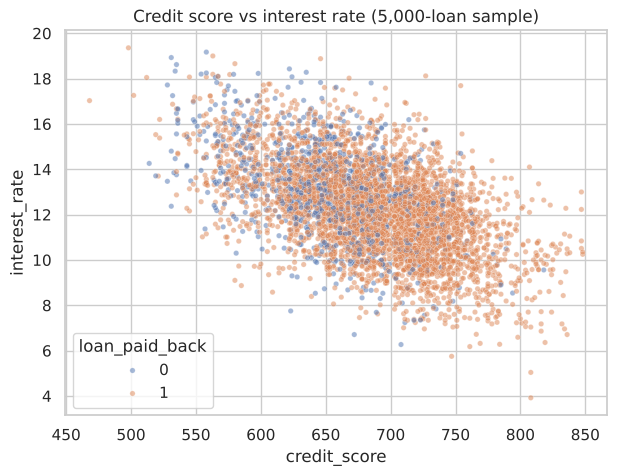

In [25]:
sample = train.sample(5000, random_state=42)

plt.figure(figsize=(7, 5))
sns.scatterplot(data=sample, x="credit_score", y="interest_rate", hue=TARGET, alpha=0.5, s=15)
plt.title("Credit score vs interest rate (5,000-loan sample)")
plt.savefig(FIG_DIR / "scatter_credit_vs_rate.png", dpi=120)
plt.show()

**Interpretation**
- Higher credit scores come with lower interest rates (risk-based pricing, r = −0.54).
- Loans that were not repaid cluster in the low-score, high-rate corner.

## Step 12 · Business data dictionary

In [26]:
business_info = [
    # (column, business meaning, data type, unit, expected risk signal, handling)
    ("id", "Unique loan application number",
     "Identifier", "-", "None", "Drop (not a feature)"),

    ("annual_income", "Borrower's yearly income; ability to repay",
     "Numeric", "USD", "Higher income → lower risk", "log1p, then scale"),

    ("debt_to_income_ratio", "Existing debt payments / income; how stretched the borrower is",
     "Numeric", "Ratio", "Higher DTI → higher risk", "log, then scale"),

    ("credit_score", "Credit bureau score; past repayment behavior",
     "Numeric", "Points (300-850)", "Higher score → lower risk", "Scale"),

    ("loan_amount", "Principal requested; size of the lender's exposure",
     "Numeric", "USD", "Larger loan → more money at risk", "Scale"),

    ("interest_rate", "Annual rate charged; lender's price for the risk",
     "Numeric", "%", "Higher rate → riskier borrower", "Scale"),

    ("gender", "Borrower gender",
     "Categorical", "-", "Should not drive credit decisions", "Fairness check only; exclude"),

    ("marital_status", "Marital status; household stability",
     "Categorical", "-", "Weak signal", "One-hot encode"),

    ("education_level", "Highest education completed; earning potential",
     "Categorical", "-", "Weak signal", "One-hot encode"),

    ("employment_status", "Current job status; stability of income",
     "Categorical", "-", "Unemployed / student → much higher risk", "One-hot encode"),

    ("loan_purpose", "What the money is for",
     "Categorical", "-", "Some purposes slightly riskier", "One-hot encode"),

    ("grade_subgrade", "Lender's internal risk grade, A1 (best) to F5 (worst)",
     "Ordinal", "-", "Worse grade → higher risk", "Ordinal encode 1-30"),

    ("loan_paid_back", "TARGET: 1 = repaid, 0 = not repaid",
     "Binary", "-", "-", "Target variable"),
]

data_dictionary = pd.DataFrame(
    business_info,
    columns=["column", "business_meaning", "data_type", "unit", "risk_signal", "handling"],
)

# add facts from the data itself
data_dictionary["missing"] = data_dictionary["column"].map(train.isna().sum())
data_dictionary["n_unique"] = data_dictionary["column"].map(train.nunique())


def value_range(col):
    if pd.api.types.is_numeric_dtype(train[col]):
        return f"{train[col].min():,.2f} to {train[col].max():,.2f}"
    return f"{train[col].nunique()} levels"


data_dictionary["observed_range"] = data_dictionary["column"].apply(value_range)

display(data_dictionary)
data_dictionary.to_csv(FIG_DIR / "data_dictionary.csv", index=False)

,column,business_meaning,data_type,unit,risk_signal,handling,missing,n_unique,observed_range
0,id,Unique loan application number,Identifier,-,None,Drop (not a feature),0,593994,"0.00 to 593,993.00"
1,annual_income,Borrower's yearly income; ability to repay,Numeric,USD,Higher income → lower risk,"log1p, then scale",0,119728,"6,002.43 to 393,381.74"
2,debt_to_income_ratio,Existing debt payments / income; how stretched...,Numeric,Ratio,Higher DTI → higher risk,"log, then scale",0,526,0.01 to 0.63
3,credit_score,Credit bureau score; past repayment behavior,Numeric,Points (300-850),Higher score → lower risk,Scale,0,399,395.00 to 849.00
4,loan_amount,Principal requested; size of the lender's expo...,Numeric,USD,Larger loan → more money at risk,Scale,0,111570,"500.09 to 48,959.95"
5,interest_rate,Annual rate charged; lender's price for the risk,Numeric,%,Higher rate → riskier borrower,Scale,0,1454,3.20 to 20.99
6,gender,Borrower gender,Categorical,-,Should not drive credit decisions,Fairness check only; exclude,0,3,3 levels
7,marital_status,Marital status; household stability,Categorical,-,Weak signal,One-hot encode,0,4,4 levels
8,education_level,Highest education completed; earning potential,Categorical,-,Weak signal,One-hot encode,0,5,5 levels
9,employment_status,Current job status; stability of income,Categorical,-,Unemployed / student → much higher risk,One-hot encode,0,5,5 levels


**Interpretation**
- The dictionary combines business meaning (from lending practice) with facts from the data (missing values, unique values, ranges).
- The `risk_signal` column records my expected relationship with default risk; these will be compared with model results later.

## Step 13 · Save cleaned data

In [27]:

test["grade_ordinal"] = test["grade_subgrade"].map(grade_map)


new_cols = ["log_annual_income", "log_debt_to_income_ratio", "grade_ordinal"]
assert train[new_cols].notna().all().all()
assert test[new_cols].notna().all().all()


train.to_csv(DATA_DIR / "train_clean.csv", index=False)
test.to_csv(DATA_DIR / "test_clean.csv", index=False)

print("train_clean:", train.shape)
print("test_clean: ", test.shape)

train_clean: (593994, 16)
test_clean:  (254569, 15)


**Interpretation**
- Saved `train_clean.csv` (593,994 × 16) and `test_clean.csv` (254,569 × 15).
- Added three columns to both sets: `log_annual_income`, `log_debt_to_income_ratio`, and `grade_ordinal`.
- Only fixed rules were applied here (type fix, log transform, ordinal mapping). Scaling and one-hot encoding will be fitted inside the modeling pipeline on training folds only, to avoid data leakage.